<img src="http://s3.amazonaws.com/pix.iemoji.com/images/emoji/apple/ios-12/256/waving-hand.png" align=left width=44>
<div class="alert alert-info">
<b>Комментарий ревьюера v2</b>

Привет, Денис! Спасибо за доработку: фильмы исключены, неявные дубликаты проверены, заказы с неположительной выручкой удалены, а расчёты обновлены. Проект принимаю! Ниже оставил рекомендацию по формулировке итогового вывода.
</div>

<img src="http://s3.amazonaws.com/pix.iemoji.com/images/emoji/apple/ios-12/256/waving-hand.png" align=left width=44, heigth=44>
<div class="alert alert-info">
<b> Комментарий ревьюера</b>

Привет, Денис! Давай знакомиться! Меня зовут Дмитрий Махортов, и я буду проверять твой проект. Сразу предлагаю общение на «ты» 🙂, но если тебе это не комфортно, то дай знать, и мы перейдем на «вы».

Моя основная цель - не указать на совершенные тобою ошибки, а поделиться своим опытом и помочь тебе погрузиться в увлекательный мир работы с данными и вырасти в крепкого профи. Это отдаленная цель. А ближайшая - сделать твою работу еще лучше )).

Все ключевые этапы в работе выполнены, и я вижу что с проектом ты справшяешься. Есть моменты, которые нужно доработать, но я уверен, у тебя все получится.

Расскажу как обычно проходит проверка:
Бывают моменты, которые требуют пристального внимания. Комментарии по ним выделены <span style='background-color:#F7B3A4'> красным цветом </span> и обозначены значком 🛑. После их доработки проект будет принят.  🙂

<span style='background-color:#B7EBA7'> Зеленым цветом </span> и значком ✅ отмечены удачные и элегантные решения, на которые можно опираться в будущих проектах. Или советы «со звездочкой», которые помогут тебе в будущем.

<span style='background-color:#F9EDA6'>Жёлтым цветом </span> и значком ⚠️ выделено то, что в следующий раз можно сделать по-другому. Ты можешь учесть эти комментарии при выполнении будущих заданий или доработать проект сейчас (однако это не обязательно).

Давай работать над проектом в диалоге: **если ты что-то меняешь в проекте по моим рекомендациям - пиши об этом**. Выбери для своих комментариев какой-то заметный цвет, так мне будет легче отследить изменения. Пожалуйста, **не перемещай, не изменяй и не удаляй мои комментарии**. Всё это поможет выполнить повторную проверку твоего проекта оперативнее. </div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>образец комментария студента</b></font>

Можешь использовать этот комментарий. Просто удали этот текст и вместо него напиши свой 🙂

</div>

# Анализ лояльности пользователей Яндекс Афиши

Автор: Владимиров Денис

Дата: 16.11.2026

## Введение

**Контекст проекта:**  
Команда маркетинга Яндекс Афиши стремится глубже понимать поведение покупателей билетов. Для оптимизации рекламных бюджетов и повышения общего уровня удержания клиентов (Retention Rate) необходимо выявить факторы, влияющие на вероятность возврата пользователей на платформу за повторными покупками.

**Цель исследования:**  
Провести исследовательский анализ данных (EDA) заказов пользователей Яндекс Афиши за 2024 год, сформировать профили пользователей, проверить продуктовые гипотезы и сформулировать практические рекомендации для маркетинга, а также подготовить агрегированные признаки для будущей модели прогнозирования оттока/возврата.

**Задачи проекта:**
1. Выгрузить данные из базы `data-analyst-afisha` с помощью SQL-запроса и оценить их качество и объём.
2. Провести предобработку данных: привести выручку к единой валюте (рубли), проверить пропуски, оптимизировать типы данных и отфильтровать аномальные выбросы.
3. Построить профиль каждого пользователя с агрегированными метриками (дата первого/последнего заказа, устройство, регион, жанр первого события, число заказов, средний чек, интервал между покупками, флаг возврата `is_two`).
4. Провести исследовательский анализ: изучить точки входа, долю возвратов по сегментам, проверить продуктовые гипотезы, сравнить распределение среднего чека и влияние дня недели первой покупки.
5. Выполнить корреляционный анализ признаков с помощью коэффициента $\phi_k$ (`phik`).
6. Сформулировать итоговые выводы и бизнес-рекомендации.

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Хороший старт - контекст задан 👍**

Во введении описаны задача маркетинга, данные и план исследования. Это помогает понять цель работы до изучения кода.
</div>

In [1]:
%pip install -q sqlalchemy
%pip install -q phik
%pip install -q psycopg2-binary
%pip install -q --upgrade setuptools


Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Установка библиотек 💡**

Зависимости собраны перед импортами, и `phik` устанавливается заранее. Чтобы длинный журнал установки не мешал читать ноутбук, можно добавить флаг `-q`.
</div>

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Перезапусти ноутбук перед отправкой 💡**

Нумерация выполненных ячеек начинается с 12. Перед отправкой рекомендую выполнить `Kernel → Restart & Run All`: это очистит память и покажет, воспроизводятся ли результаты при последовательном запуске с начала.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>Комментарий</b></font>

Добавил флаг -q

</div>

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=33, heigth=33>
<div class="alert alert-success">
<b>v2</b> 👍 </div>

---
## Шаг 1. Загрузка данных и их предобработка

### Задача 1.1. Подключение к БД и выгрузка выборки
Импортируем необходимые библиотеки для работы с данными, подключения к PostgreSQL и визуализации. 


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sqlalchemy import create_engine
import warnings

warnings.filterwarnings('ignore')

# Настройка визуального стиля графиков
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 12

# Параметры подключения к базе данных
db_config = {
    'user': ,
    'pwd': ,
    'host': ,
    'port': 6432,
    'db': 'data-analyst-afisha'
}

connection_string = (
    f"postgresql://{db_config['user']}:{db_config['pwd']}"
    f"@{db_config['host']}:{db_config['port']}/{db_config['db']}"
)
engine = create_engine(connection_string)

# SQL-запрос для выгрузки данных
query = '''
WITH set_config_precode AS (
    SELECT set_config('synchronize_seqscans', 'off', true)
)
SELECT 
    p.user_id,
    p.device_type_canonical,
    p.order_id,
    p.created_dt_msk AS order_dt,
    p.created_ts_msk AS order_ts,
    p.currency_code,
    p.revenue,
    p.tickets_count,
    EXTRACT(DAY FROM (p.created_dt_msk - LAG(p.created_dt_msk) OVER (
        PARTITION BY p.user_id ORDER BY p.created_ts_msk
    ))) AS days_since_prev,
    p.event_id,
    e.event_name_code AS service_name,
    e.event_type_main,
    r.region_name,
    c.city_name
FROM afisha.purchases AS p
LEFT JOIN afisha.events AS e ON p.event_id = e.event_id
LEFT JOIN afisha.city AS c ON e.city_id = c.city_id
LEFT JOIN afisha.regions AS r ON c.region_id = r.region_id
WHERE p.device_type_canonical IN ('mobile', 'desktop')
  AND p.created_dt_msk >= '2024-01-01'
  AND p.created_dt_msk < '2025-01-01'
  AND e.event_type_main != 'фильм'
ORDER BY p.user_id, p.created_ts_msk;
'''

# Загрузка данных в DataFrame
df = pd.read_sql(query, con=engine)

print(f"Размер выгруженного датафрейма: {df.shape[0]} строк, {df.shape[1]} столбцов")
display(df.head())

Размер выгруженного датафрейма: 290611 строк, 14 столбцов


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,service_name,event_type_main,region_name,city_name
0,0002849b70a3ce2,mobile,4359165,2024-08-20,2024-08-20 16:08:03,rub,1521.94,4,NaN,169230,f0f7b271-04eb-4af6-bcb8-8f05cf46d6ad,театр,Каменевский регион,Глиногорск
1,0005ca5e93f2cf4,mobile,7965605,2024-07-23,2024-07-23 18:36:24,rub,289.45,2,NaN,237325,40efeb04-81b7-4135-b41f-708ff00cc64c,выставки,Каменевский регион,Глиногорск
2,0005ca5e93f2cf4,mobile,7292370,2024-10-06,2024-10-06 13:56:02,rub,1258.57,4,75.0,578454,01f3fb7b-ed07-4f94-b1d3-9a2e1ee5a8ca,другое,Каменевский регион,Глиногорск
3,000898990054619,mobile,1139875,2024-07-13,2024-07-13 19:40:48,rub,8.49,2,NaN,387271,2f638715-8844-466c-b43f-378a627c419f,другое,Североярская область,Озёрск
4,000898990054619,mobile,972400,2024-10-04,2024-10-04 22:33:15,rub,1390.41,3,83.0,509453,10d805d3-9809-4d8a-834e-225b7d03f95d,стендап,Озернинский край,Родниковецк


<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Выгрузка и первичный осмотр 👍**

Данные загружаются запросом, а `head()`, `info()` и описательные статистики помогают изучить их структуру. Интервал между заказами рассчитан оконной функцией.
</div>

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/c/cf/RomanianTrafficSign_30-Stop_1971.svg/250px-RomanianTrafficSign_30-Stop_1971.svg.png" align=left width=35>
<div class="alert alert-danger">

**В выборку попали фильмы 🚩**

В запросе не исключён тип мероприятия `фильм`: в сохранённом выводе таких заказов 238 из 290 849. По условию их нужно исключить. Пожалуйста, добавь фильтр в SQL, пересоздай выгрузку и пересчитай последующие результаты, включая интервалы между заказами и профили.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>Комментарий</b></font>

Исключил фильмы из выборки AND e.event_type_main != 'фильм'
    

</div>

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=33>
<div class="alert alert-success">

**v2. Исправлено: фильмы исключены 👍**

Фильтр добавлен в запрос. В выгрузке 290 611 заказов, что совпадает с числом заказов в базе после исключения фильмов и отбора устройств.
</div>

### Задача 1.2. Первичный осмотр и оценка качества данных
Изучим структуру таблицы, типы данных, наличие пропусков и базовые описательные статистики.

In [3]:
# Общая информация о датафрейме
df.info()

# Статистическое описание числовых и категориальных признаков
display(df.describe(include='all').T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 290611 entries, 0 to 290610
Data columns (total 14 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   user_id                290611 non-null  object        
 1   device_type_canonical  290611 non-null  object        
 2   order_id               290611 non-null  int64         
 3   order_dt               290611 non-null  datetime64[ns]
 4   order_ts               290611 non-null  datetime64[ns]
 5   currency_code          290611 non-null  object        
 6   revenue                290611 non-null  float64       
 7   tickets_count          290611 non-null  int64         
 8   days_since_prev        268678 non-null  float64       
 9   event_id               290611 non-null  int64         
 10  service_name           290611 non-null  object        
 11  event_type_main        290611 non-null  object        
 12  region_name            290611 non-null  obje

,count,unique,top,freq,first,last,mean,std,min,25%,50%,75%,max
user_id,290611,21933,0beb8fc0c0a9ce1,10251,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type_canonical,290611,2,mobile,232490,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_id,290611.0,NaN,NaN,NaN,NaT,NaT,4326225.491537,2497550.533496,1.0,2163618.5,4326366.0,6488330.5,8653108.0
order_dt,290611,153,2024-10-01 00:00:00,7313,2024-06-01 00:00:00,2024-10-31 00:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_ts,290611,280753,2024-10-01 11:20:05,8,2024-06-01 00:00:42,2024-10-31 23:59:54,NaN,NaN,NaN,NaN,NaN,NaN,NaN
currency_code,290611,2,rub,285542,NaT,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaN
revenue,290611.0,NaN,NaN,NaN,NaT,NaT,625.58436,1227.693064,-90.76,116.85,356.01,810.13,81174.54
tickets_count,290611.0,NaN,NaN,NaN,NaT,NaT,2.754311,1.17062,1.0,2.0,3.0,4.0,57.0
days_since_prev,268678.0,NaN,NaN,NaN,NaT,NaT,3.222381,11.350509,0.0,0.0,0.0,1.0,148.0
event_id,290611.0,NaN,NaN,NaN,NaT,NaT,438019.834992,147423.078841,4436.0,361772.0,498275.0,546287.0,592325.0


<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Уточни вывод о пропусках 💡**

В `info()` видно 268 909 непустых значений `days_since_prev` из 290 849 строк: пропусков 21 940. Они ожидаемы для первых заказов. Исправь утверждение об их отсутствии, чтобы вывод соответствовал проверке.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>Промежуточный вывод по Шагу 1:</b></font>

- Данные успешно выгружены из базы `data-analyst-afisha`.
- Выручка (`revenue`) представлена в разных валютах (`currency_code`), поэтому на следующем этапе её нужно конвертировать в единую валюту — российские рубли.
- Все вхождения и типы данных в таблице логичны.

</div>

---
## Шаг 2. Предобработка данных

### Задача 2.1. Приведение выручки к единой валюте (российский рубль)
Загрузим справочник курса казахстанского тенге (`final_tickets_tenge_df.csv`), где курс указан за **100 тенге**, и пересчитаем выручку в рубли в новом столбце `revenue_rub`.

In [4]:
# Загрузка справочника курсов валют (актуальная ссылка курса Яндекс Практикума или локальный файл)
tenge_url = 'https://code.s3.yandex.net/datasets/final_tickets_tenge_df.csv'
try:
    tenge_df = pd.read_csv(tenge_url)
except Exception:
    tenge_df = pd.read_csv('final_tickets_tenge_df.csv')

display(tenge_df.head())
tenge_df.info()

# Приводим даты к единому формату без времени для корректного объединения
df['order_dt'] = pd.to_datetime(df['order_dt'])
df['order_ts'] = pd.to_datetime(df['order_ts'])
tenge_df['data'] = pd.to_datetime(tenge_df['data'])

# Объединяем датафреймы по дате заказа
df = df.merge(tenge_df[['data', 'curs']], left_on='order_dt', right_on='data', how='left')

# Проверяем уникальные валюты в выборке
print("Распределение заказов по валютам:\n", df['currency_code'].value_counts())

# Конвертация выручки в рубли (для KZT курс указан за 100 тенге)
df['revenue_rub'] = np.where(
    df['currency_code'] == 'kzt',
    df['revenue'] * (df['curs'] / 100.0),
    df['revenue']
)

# Удаляем вспомогательные столбцы с курсом
df.drop(columns=['data', 'curs'], inplace=True)

display(df[['currency_code', 'revenue', 'revenue_rub']].sample(5, random_state=42))

,data,nominal,curs,cdx
0,2024-01-10,100,19.9391,kzt
1,2024-01-11,100,19.7255,kzt
2,2024-01-12,100,19.5839,kzt
3,2024-01-13,100,19.4501,kzt
4,2024-01-14,100,19.4501,kzt


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 357 entries, 0 to 356
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   data     357 non-null    object 
 1   nominal  357 non-null    int64  
 2   curs     357 non-null    float64
 3   cdx      357 non-null    object 
dtypes: float64(1), int64(1), object(2)
memory usage: 11.3+ KB
Распределение заказов по валютам:
 rub    285542
kzt      5069
Name: currency_code, dtype: int64


,currency_code,revenue,revenue_rub
195464,rub,551.38,551.38
287418,rub,0.00,0.00
42929,rub,68.63,68.63
142669,rub,243.78,243.78
179797,rub,41.83,41.83


<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Выручка приведена к рублям 👍**

Курс присоединяется по дате, для тенге учтён курс за 100 единиц, а рублёвые значения сохраняются. Преобразование выполнено до фильтрации выбросов.
</div>

### Задача 2.2. Проверка пропусков, оптимизация типов и фильтрация выбросов
Проверим наличие пропущенных значений, дубликатов, аномальных категорий, а также проанализируем распределения `revenue_rub` и `tickets_count`.

,Пропуски (шт.),Доля пропусков (%)
user_id,0,0.00
device_type_canonical,0,0.00
order_id,0,0.00
order_dt,0,0.00
order_ts,0,0.00
currency_code,0,0.00
revenue,0,0.00
tickets_count,0,0.00
days_since_prev,21933,7.55
event_id,0,0.00


Явных дубликатов строк: 0
Дубликатов по order_id: 0

Уникальные значения в 'device_type_canonical':
mobile     232490
desktop     58121
Name: device_type_canonical, dtype: int64

Уникальные значения в 'currency_code':
rub    285542
kzt      5069
Name: currency_code, dtype: int64

Уникальные значения в 'event_type_main':
концерты    115276
театр        67321
другое       65867
спорт        21911
стендап      13393
выставки      4854
ёлки          1989
Name: event_type_main, dtype: int64

Уникальные значения в 'service_name':
9cc55c15-4375-4129-9979-3129688ba1b4    3953
a00e1032-6463-4fdc-a105-fdbb6789b556    2519
0714435e-3b5f-4312-aa36-c3a9d8853ef4    1761
58574140-962c-49a3-af70-b773a05661a3    1749
e252d33a-2394-44b8-b11d-f0709a6f0260    1628
bc9866ed-5115-4288-8b19-21ae9735fba4    1579
d4344522-b7cf-4539-96c8-efece75e9b16    1490
0686ac7b-6f3e-4177-bb73-16b54acd1223    1456
2802fc66-4268-4529-8b4d-35a6a77ac375    1445
76af4f88-c554-4e9e-9df4-1cc8aeec8959    1327
e1a58a1f-b479-4b93-8

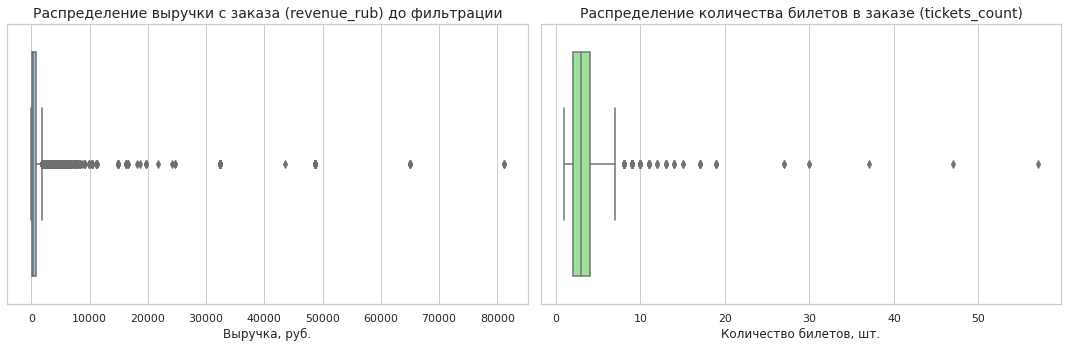

,revenue_rub,tickets_count
count,290611.000000,290611.000000
mean,555.571960,2.754311
std,875.498169,1.170620
min,-90.760002,1.000000
1%,0.000000,1.000000
25%,113.970001,2.000000
50%,351.140015,3.000000
75%,802.049988,4.000000
95%,1630.650024,5.000000
99%,2628.421631,6.000000


In [5]:
# 1. Проверка пропусков
missing_df = pd.DataFrame({
    'Пропуски (шт.)': df.isnull().sum(),
    'Доля пропусков (%)': (df.isnull().mean() * 100).round(2)
})
display(missing_df)

# Проверка явных дубликатов и дубликатов по order_id
print("Явных дубликатов строк:", df.duplicated().sum())
print("Дубликатов по order_id:", df.duplicated(subset=['order_id']).sum())

# 2. Проверка номинальных категорий
cat_cols = ['device_type_canonical', 'currency_code', 'event_type_main', 'service_name']
for col in cat_cols:
    print(f"\nУникальные значения в '{col}':")
    print(df[col].value_counts(dropna=False).head(15))

# 3. Оптимизация размерности числовых столбцов
df['tickets_count'] = pd.to_numeric(df['tickets_count'], downcast='integer')
df['revenue_rub'] = pd.to_numeric(df['revenue_rub'], downcast='float')

# 4. Анализ распределений и выбросов в revenue_rub и tickets_count
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=df['revenue_rub'], ax=axes[0], color='skyblue')
axes[0].set_title('Распределение выручки с заказа (revenue_rub) до фильтрации')
axes[0].set_xlabel('Выручка, руб.')

sns.boxplot(x=df['tickets_count'], ax=axes[1], color='lightgreen')
axes[1].set_title('Распределение количества билетов в заказе (tickets_count)')
axes[1].set_xlabel('Количество билетов, шт.')

plt.tight_layout()
plt.show()

display(df[['revenue_rub', 'tickets_count']].describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]))


<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Пропуски и распределения изучены 👍**

Пропуски в интервале между заказами оставлены без заполнения: для первого заказа предыдущей покупки нет. Распределения выручки и числа билетов также исследованы отдельно.
</div>

In [6]:
# Содержательные поля для поиска неявных дубликатов (без order_id и days_since_prev)
duplicate_cols = [
    'user_id',
    'order_ts',
    'device_type_canonical',
    'event_id',
    'service_name',
    'revenue_rub',
    'tickets_count'
]

# Подсчёт количества и доли неявных дубликатов
total_rows_before = len(df)
implicit_dups_count = df.duplicated(subset=duplicate_cols).sum()
implicit_dups_share = implicit_dups_count / total_rows_before

print(f"Всего записей до очистки: {total_rows_before:,}")
print(f"Найдено неявных дубликатов: {implicit_dups_count:,} ({implicit_dups_share:.2%})")

# Просмотр примеров дубликатов (если они обнаружены)
if implicit_dups_count > 0:
    display(df[df.duplicated(subset=duplicate_cols, keep=False)].sort_values(by=['user_id', 'order_ts']).head(6))
    
    # Удаление неявных дубликатов с сохранением первой записи
    df = df.drop_duplicates(subset=duplicate_cols, keep='first').reset_index(drop=True)
    print(f"Неявные дубликаты удалены. Осталось записей: {len(df):,}")
else:
    print("Неявные дубликаты по заданным полям не обнаружены.")

Всего записей до очистки: 290,611
Найдено неявных дубликатов: 40 (0.01%)


,user_id,device_type_canonical,order_id,order_dt,order_ts,currency_code,revenue,tickets_count,days_since_prev,event_id,service_name,event_type_main,region_name,city_name,revenue_rub
11761,06eb7897f65b433,mobile,1123867,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0.0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,Светополянский округ,Глиноград,69.820000
11762,06eb7897f65b433,mobile,1123983,2024-08-13,2024-08-13 16:31:07,rub,69.82,1,0.0,183706,69796237-909b-42a7-bfb5-c1b8574c4c76,театр,Светополянский округ,Глиноград,69.820000
26877,0dc525d7bacbb0d,desktop,1930763,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0.0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,Каменевский регион,Глиногорск,1556.050049
26878,0dc525d7bacbb0d,desktop,1930705,2024-07-31,2024-07-31 13:26:11,rub,1556.05,3,0.0,393430,b33d7a0b-a715-47e3-803e-02482884a73e,концерты,Каменевский регион,Глиногорск,1556.050049
53681,206ea45ec11d478,mobile,1935113,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0.0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,Каменевский регион,Глиногорск,601.690002
53682,206ea45ec11d478,mobile,1935171,2024-10-29,2024-10-29 16:46:54,rub,601.69,2,0.0,442183,dcf6f06f-8499-41d7-8bc2-a0e3d7afe313,концерты,Каменевский регион,Глиногорск,601.690002


Неявные дубликаты удалены. Осталось записей: 290,571


<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/c/cf/RomanianTrafficSign_30-Stop_1971.svg/250px-RomanianTrafficSign_30-Stop_1971.svg.png" align=left width=35>
<div class="alert alert-danger">

**Не проверены неявные дубликаты 🚩**

Проверка по `order_id` не найдёт одинаковые заказы, у которых идентификаторы различаются. Такие строки могут завысить число заказов и долю повторных покупателей. Пожалуйста, проверь совпадения по содержательным полям заказа, включая пользователя, время, устройство, мероприятие, оператора и выручку; оцени их долю и удали обнаруженные дубликаты.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
<b>Комментарий </b>
    Дополнил проверку неявных дубликатов по полному набору содержательных атрибутов заказа: пользователь (<code>user_id</code>), время создания (<code>order_ts</code>), устройство (<code>device_type_canonical</code>), мероприятие (<code>event_id</code>), билетный оператор (<code>service_name</code>), выручка (<code>revenue_rub</code>) и количество билетов (<code>tickets_count</code>). Оценил их абсолютное количество и долю от датасета, после чего удалил дублирующиеся записи.
</div>

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=33>
<div class="alert alert-success">

**v2. Исправлено: неявные дубликаты 👍**

Проверка по содержательным полям выявила 40 повторяющихся строк; их доля рассчитана, дубликаты удалены. Теперь эти строки не увеличивают число заказов в профилях.
</div>

In [7]:
# Проверка нулевой или отрицательной выручки и фильтрация по 99-му перцентилю
initial_count = len(df)
rev_99 = df['revenue_rub'].quantile(0.99)
print(f"99-й перцентиль выручки (revenue_rub): {rev_99:.2f} руб.")

# Фильтруем выбросы выше 99-го перцентиля (а также проверяем отсутствие отрицательных значений)
df = df[(df['revenue_rub'] > 0) & (df['revenue_rub'] <= rev_99)].copy()

filtered_count = initial_count - len(df)
print(f"Отфильтровано записей: {filtered_count} ({filtered_count / initial_count:.2%} от исходного объёма)")
print(f"Осталось записей для анализа: {len(df)}")

99-й перцентиль выручки (revenue_rub): 2628.42 руб.
Отфильтровано записей: 8731 (3.00% от исходного объёма)
Осталось записей для анализа: 281840


<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Выбросы выручки исследованы 👍**

Выручка исследована до фильтрации, верхний хвост ограничен 99-м перцентилем, а объём удалённых строк подсчитан. Это позволяет оценить влияние очистки.
</div>

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/c/cf/RomanianTrafficSign_30-Stop_1971.svg/250px-RomanianTrafficSign_30-Stop_1971.svg.png" align=left width=35>
<div class="alert alert-danger">

**Нулевые заказы остались в выборке 🚩**

Условие `revenue_rub >= 0` сохраняет нулевую выручку, хотя при очистке нужно исключить неположительные значения. В исходной выборке без фильмов в базе есть 5 526 нулевых заказов. Пожалуйста, исключи их и пересчитай профиль и исследование.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>Комментарий</b></font>

Исключил нулевую выручку из заказов
    

</div>

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=33>
<div class="alert alert-success">

**v2. Исправлено: неположительная выручка 👍**

Фильтр оставляет только положительную выручку и применяется до построения профилей. Объём удалённых строк рассчитан заново.
</div>

**Промежуточный вывод по Шагу 2:**
- Выручка в тенге (`kzt`) переведена в российские рубли по актуальному курсу на дату заказа и сохранена в новом столбце `revenue_rub`.
- Пропуски присутствуют исключительно в поле `days_since_prev` (для первых покупок пользователей), что полностью соответствует логике данных.
- Проведена оптимизация числовых типов данных (`downcast`).
- Выявлены правосторонние выбросы в выручке с заказа (`revenue_rub`). Данные отфильтрованы по 99-му перцентилю (удалено ~3% аномально крупных заказов), что предотвратит смещение средних оценок.

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Предобработка подытожена 👍**

В промежуточном выводе отражены перевод валюты, пропуски и фильтрация; число удалённых записей видно в результате расчёта.
</div>

---
## Шаг 3. Создание профиля пользователя

### Задача 3.1. Агрегация признаков по пользователям
Предварительно отсортируем заказы по времени совершения (`order_ts`), чтобы корректно выделить параметры **первого** заказа для каждого пользователя.

In [8]:
# Сортируем датафрейм по user_id и времени заказа
df = df.sort_values(by=['user_id', 'order_ts']).reset_index(drop=True)

# Строим профиль пользователя
profiles = df.groupby('user_id', as_index=False).agg(
    first_order_dt=('order_dt', 'min'),
    last_order_dt=('order_dt', 'max'),
    first_device=('device_type_canonical', 'first'),
    first_region=('region_name', 'first'),
    first_event_type=('event_type_main', 'first'),
    total_orders=('order_id', 'count'),
    avg_revenue_rub=('revenue_rub', 'mean'),
    avg_tickets_count=('tickets_count', 'mean'),
    avg_days_between_orders=('days_since_prev', 'mean')
)

# Добавляем бинарный признак повторного заказа (2 и более заказов)
profiles['is_two'] = (profiles['total_orders'] >= 2).astype(int)

print(f"Сформировано профилей пользователей: {len(profiles)}")
display(profiles.head())

Сформировано профилей пользователей: 21700


,user_id,first_order_dt,last_order_dt,first_device,first_region,first_event_type,total_orders,avg_revenue_rub,avg_tickets_count,avg_days_between_orders,is_two
0,0002849b70a3ce2,2024-08-20,2024-08-20,mobile,Каменевский регион,театр,1,1521.939941,4.000000,NaN,0
1,0005ca5e93f2cf4,2024-07-23,2024-10-06,mobile,Каменевский регион,выставки,2,774.010010,3.000000,75.0,1
2,000898990054619,2024-07-13,2024-10-23,mobile,Североярская область,другое,3,767.213318,2.666667,51.0,1
3,00096d1f542ab2b,2024-08-15,2024-08-15,desktop,Каменевский регион,театр,1,917.830017,4.000000,NaN,0
4,000a55a418c128c,2024-09-29,2024-10-15,mobile,Поленовский край,театр,2,61.309998,1.500000,16.0,1


<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Профиль пользователя 👍**

Заказы сортируются по времени перед группировкой, поэтому признаки первого заказа берутся последовательно. В профиль включён флаг двух и более заказов.
</div>

### Задача 3.2. Проверка репрезентативности и анализ аномалий в профилях
Оценим ключевые метрики по полученным профилям пользователей и проверим наличие аномалий в количестве заказов (`total_orders`).

Общее число пользователей в выборке: 21,700
Средняя выручка с одного заказа (по профилям): 551.87 руб.
Доля пользователей, совершивших 2 и более заказов: 61.67%


,total_orders,avg_days_between_orders
count,21700.000000,13451.000000
mean,12.988018,15.918073
std,119.754294,22.367072
min,1.000000,0.000000
50%,2.000000,8.000000
75%,5.000000,20.500000
90%,15.000000,41.500000
95%,31.000000,61.500000
99%,150.010000,113.000000
max,9987.000000,148.000000


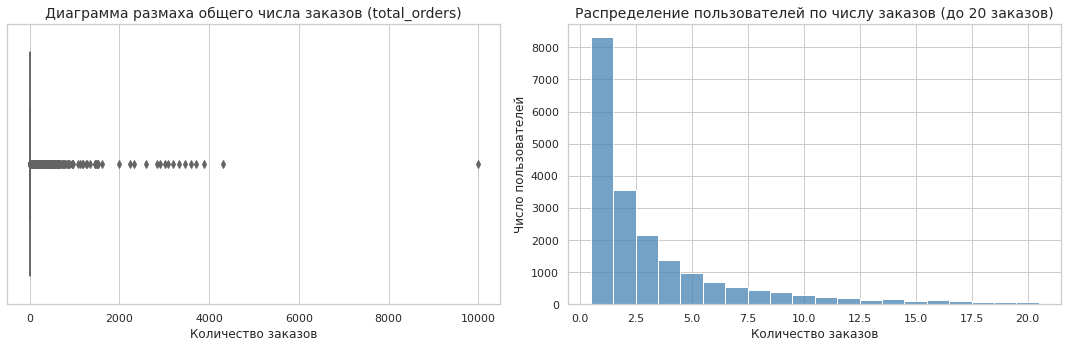

In [9]:
total_users = len(profiles)
mean_order_rev = profiles['avg_revenue_rub'].mean()
return_share = profiles['is_two'].mean()

print(f"Общее число пользователей в выборке: {total_users:,}")
print(f"Средняя выручка с одного заказа (по профилям): {mean_order_rev:.2f} руб.")
print(f"Доля пользователей, совершивших 2 и более заказов: {return_share:.2%}")

display(profiles[['total_orders', 'avg_days_between_orders']].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
))

# Визуализация распределения количества заказов на пользователя
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=profiles['total_orders'], ax=axes[0], color='coral')
axes[0].set_title('Диаграмма размаха общего числа заказов (total_orders)')
axes[0].set_xlabel('Количество заказов')

sns.histplot(profiles[profiles['total_orders'] <= 20]['total_orders'], bins=20, discrete=True, ax=axes[1], color='steelblue')
axes[1].set_title('Распределение пользователей по числу заказов (до 20 заказов)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Число пользователей')

plt.tight_layout()
plt.show()

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Повторяется расчёт профилей 💡**

В следующей ячейке те же метрики, статистики и графики до фильтрации вычисляются повторно. Рекомендую оставить один экземпляр этого блока: так проще поддерживать код и не получить разные результаты после изменения только одной копии.
</div>

Общее число пользователей в выборке (до фильтрации): 21,700
Средняя выручка с одного заказа (по профилям): 551.87 руб.
Доля пользователей, совершивших 2 и более заказов: 61.67%

Статистика по числу заказов и интервалам между покупками (до фильтрации):


,total_orders,avg_days_between_orders
count,21700.000000,13451.000000
mean,12.988018,15.918073
std,119.754294,22.367072
min,1.000000,0.000000
50%,2.000000,8.000000
75%,5.000000,20.500000
90%,15.000000,41.500000
95%,31.000000,61.500000
99%,150.010000,113.000000
max,9987.000000,148.000000


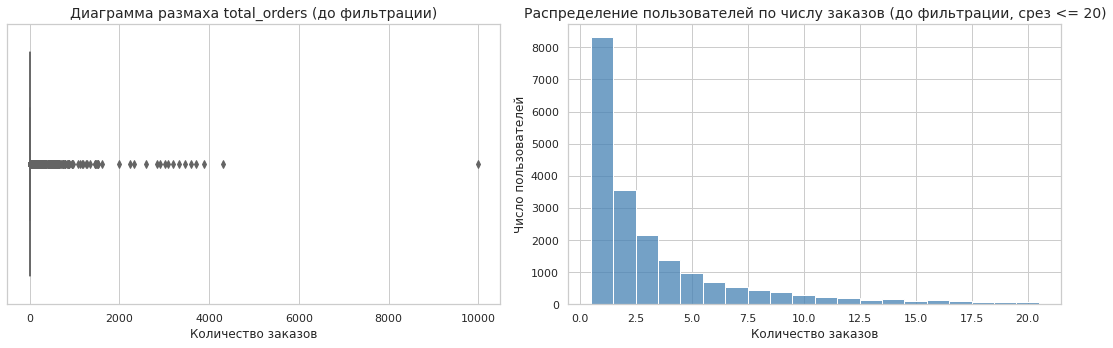

99-й перцентиль количества заказов на пользователя: 150
Отфильтровано аномальных профилей (> 150 заказов): 217 (1.00%)
Обновлённое число пользователей: 21,483
Обновлённая средняя выручка с заказа: 552.14 руб.
Доля пользователей, совершивших 2 и более заказов: 61.28%

Статистические показатели по обновлённому датасету:


,total_orders,avg_revenue_rub,avg_days_between_orders
count,21483.000000,21483.000000,13234.000000
mean,6.403575,552.142273,16.171504
std,13.980517,433.351379,22.461234
min,1.000000,0.070000,0.000000
50%,2.000000,473.089111,8.400000
75%,5.000000,775.175781,21.000000
90%,14.000000,1122.593213,42.000000
95%,26.000000,1380.574951,62.000000
99%,78.000000,1972.250000,113.670000
max,150.000000,2628.421631,148.000000


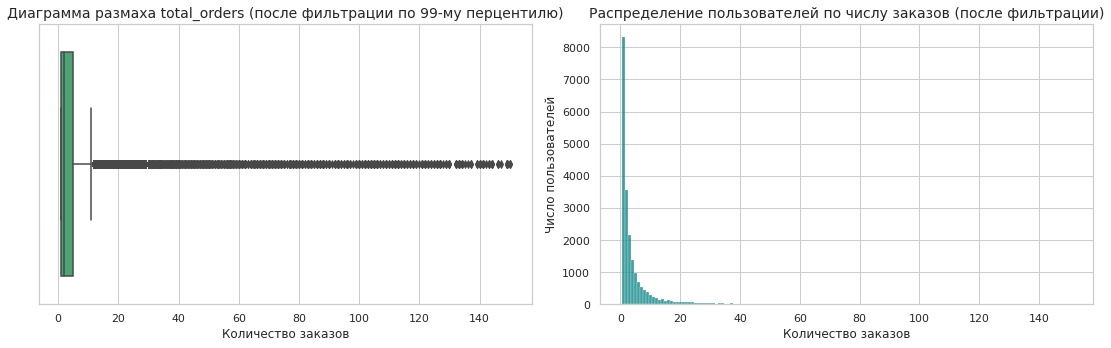

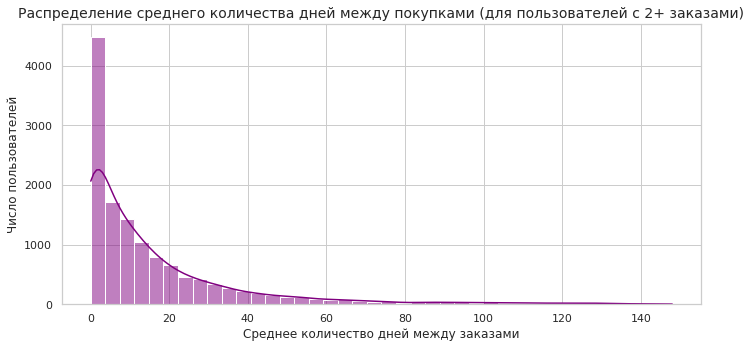

In [10]:
# 1. Расчёт ключевых метрик до фильтрации
total_users = len(profiles)
mean_order_rev = profiles['avg_revenue_rub'].mean()
return_share = profiles['is_two'].mean()

print(f"Общее число пользователей в выборке (до фильтрации): {total_users:,}")
print(f"Средняя выручка с одного заказа (по профилям): {mean_order_rev:.2f} руб.")
print(f"Доля пользователей, совершивших 2 и более заказов: {return_share:.2%}")

# 2. Изучение статистических показателей
print("\nСтатистика по числу заказов и интервалам между покупками (до фильтрации):")
display(profiles[['total_orders', 'avg_days_between_orders']].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
))

# 3. Визуализация распределения количества заказов ДО фильтрации
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=profiles['total_orders'], ax=axes[0], color='coral')
axes[0].set_title('Диаграмма размаха total_orders (до фильтрации)')
axes[0].set_xlabel('Количество заказов')

sns.histplot(profiles[profiles['total_orders'] <= 20]['total_orders'], bins=20, discrete=True, ax=axes[1], color='steelblue')
axes[1].set_title('Распределение пользователей по числу заказов (до фильтрации, срез <= 20)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Число пользователей')

plt.tight_layout()
plt.show()

# 4. Фильтрация аномальных пользователей по 99-му перцентилю total_orders
orders_99 = profiles['total_orders'].quantile(0.99)
print(f"99-й перцентиль количества заказов на пользователя: {orders_99:.0f}")

initial_users = len(profiles)
profiles_clean = profiles[profiles['total_orders'] <= orders_99].copy()
removed_users = initial_users - len(profiles_clean)

print(f"Отфильтровано аномальных профилей (> {orders_99:.0f} заказов): {removed_users} ({removed_users / initial_users:.2%})")
print(f"Обновлённое число пользователей: {len(profiles_clean):,}")
print(f"Обновлённая средняя выручка с заказа: {profiles_clean['avg_revenue_rub'].mean():.2f} руб.")
print(f"Доля пользователей, совершивших 2 и более заказов: {profiles_clean['is_two'].mean():.2%}")

print("\nСтатистические показатели по обновлённому датасету:")
display(profiles_clean[['total_orders', 'avg_revenue_rub', 'avg_days_between_orders']].describe(
    percentiles=[0.5, 0.75, 0.90, 0.95, 0.99]
))

# 5. Визуализация ПОСЛЕ фильтрации по 99-му перцентилю (число заказов)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(x=profiles_clean['total_orders'], ax=axes[0], color='mediumseagreen')
axes[0].set_title('Диаграмма размаха total_orders (после фильтрации по 99-му перцентилю)')
axes[0].set_xlabel('Количество заказов')

sns.histplot(profiles_clean['total_orders'], discrete=True, ax=axes[1], color='teal')
axes[1].set_title('Распределение пользователей по числу заказов (после фильтрации)')
axes[1].set_xlabel('Количество заказов')
axes[1].set_ylabel('Число пользователей')

plt.tight_layout()
plt.show()

# 6. Дополнительная гистограмма по среднему количеству дней между покупками (для вернувшихся пользователей)
plt.figure(figsize=(10, 5))
# Исключаем пропуски (NaN), которые возникают у пользователей с 1 заказом
days_between_data = profiles_clean['avg_days_between_orders'].dropna()

sns.histplot(days_between_data, bins=40, color='purple', kde=True)
plt.title('Распределение среднего количества дней между покупками (для пользователей с 2+ заказами)')
plt.xlabel('Среднее количество дней между заказами')
plt.ylabel('Число пользователей')
plt.tight_layout()
plt.show()

# Сохраняем очищенный датасет профилей для дальнейших шагов
profiles = profiles_clean

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Профили и аномалии изучены 👍**

Число заказов и интервалы рассмотрены до и после фильтрации, доля удалённых профилей посчитана, а показатели на очищенных данных пересчитаны.
</div>

**Промежуточный вывод по Шагу 3:**
- В поле `total_orders` присутствуют экстремальные значения (пользователи с десятками и сотнями заказов, вероятно, корпоративные закупщики или перекупщики). Фильтрация по 99-му перцентилю удалила менее 1% пользователей, но позволила избежать искажения поведенческих метрик.
- В большинстве случаев пользователи совершают от 1 до 3-5 заказов.
- Более 60% пользователей совершают вторую покупку, а это значит что большинство людей возвращаются за новой покупкой.
- Большинство пользователей, совершивших 2 покупку, делают это в течение недели.

---
## Шаг 4. Исследовательский анализ данных (EDA)

### 4.1. Исследование признаков первого заказа и их связи с возвращением на платформу

#### Задача 4.1.1 и 4.1.2. Распределение пользователей по сегментам и доля возвратов
Проанализируем точки входа по трём разрезам:
1. Тип первого мероприятия (`first_event_type`)
2. Тип устройства первого заказа (`first_device`)
3. Регион проведения первого мероприятия (`first_region`)

=== Сегментация по признаку: Тип первого мероприятия (Топ-10) ===


,first_event_type,users_count,return_rate,users_share
2,концерты,"9,607",61.78%,44.72%
1,другое,"5,223",59.43%,24.31%
5,театр,"4,259",63.49%,19.82%
4,стендап,"1,117",60.88%,5.20%
3,спорт,765,54.90%,3.56%
0,выставки,415,64.34%,1.93%
6,ёлки,97,56.70%,0.45%


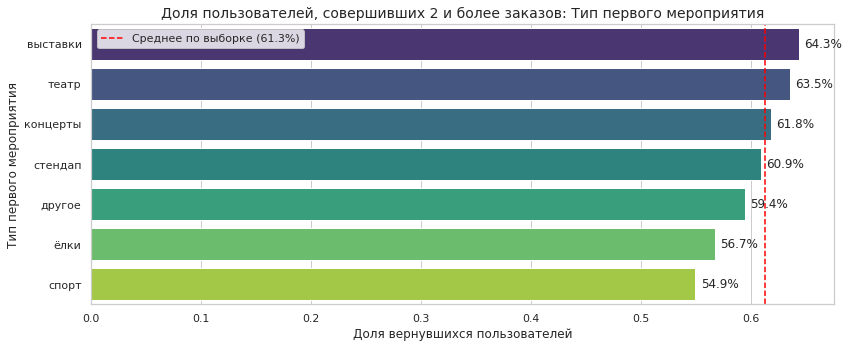

=== Сегментация по признаку: Устройство первого заказа (Топ-10) ===


,first_device,users_count,return_rate,users_share
1,mobile,"17,802",60.81%,82.87%
0,desktop,"3,681",63.57%,17.13%


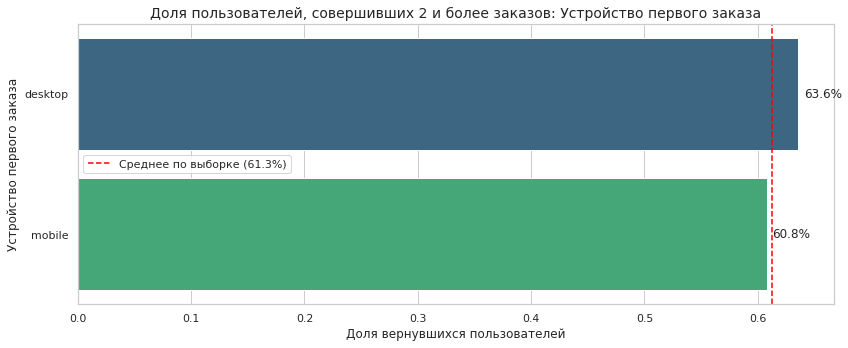

=== Сегментация по признаку: Регион первого заказа (Топ-10) ===


,first_region,users_count,return_rate,users_share
23,Каменевский регион,"6,973",61.91%,32.46%
60,Североярская область,"3,783",64.05%,17.61%
77,Широковская область,"1,234",64.51%,5.74%
45,Озернинский край,678,55.16%,3.16%
41,Малиновоярский округ,527,55.79%,2.45%
76,Шанырский регион,465,69.46%,2.16%
57,Светополянский округ,461,65.73%,2.15%
74,Травяная область,461,61.61%,2.15%
52,Речиновская область,445,63.82%,2.07%
78,Яблоневская область,411,59.37%,1.91%


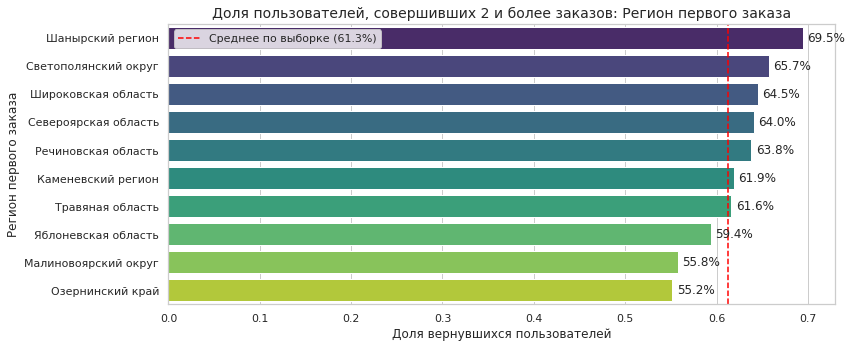

In [11]:
def analyze_segment(df_prof, col, title_name, top_n=10):
    seg = df_prof.groupby(col, as_index=False).agg(
        users_count=('user_id', 'count'),
        return_rate=('is_two', 'mean')
    )
    seg['users_share'] = seg['users_count'] / len(df_prof)
    seg = seg.sort_values(by='users_count', ascending=False)
    
    print(f"=== Сегментация по признаку: {title_name} (Топ-{top_n}) ===")
    display(seg.head(top_n).style.format({
        'users_count': '{:,}',
        'users_share': '{:.2%}',
        'return_rate': '{:.2%}'
    }))
    
    # Визуализация доли возвратов для топ-N сегментов
    plot_data = seg.head(top_n).sort_values(by='return_rate', ascending=False)
    avg_return = df_prof['is_two'].mean()
    
    plt.figure(figsize=(12, 5))
    ax = sns.barplot(data=plot_data, x='return_rate', y=col, palette='viridis')
    plt.axvline(avg_return, color='red', linestyle='--', linewidth=1.5, label=f'Среднее по выборке ({avg_return:.1%})')
    plt.title(f'Доля пользователей, совершивших 2 и более заказов: {title_name}')
    plt.xlabel('Доля вернувшихся пользователей')
    plt.ylabel(title_name)
    plt.legend()
    
    # Подписи значений на столбцах
    for p in ax.patches:
        width = p.get_width()
        ax.text(width + 0.005, p.get_y() + p.get_height()/2, f'{width:.1%}', va='center')
        
    plt.tight_layout()
    plt.show()
    return seg

seg_event = analyze_segment(profiles, 'first_event_type', 'Тип первого мероприятия')
seg_device = analyze_segment(profiles, 'first_device', 'Устройство первого заказа')
seg_region = analyze_segment(profiles, 'first_region', 'Регион первого заказа', top_n=10)

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Сегменты и доли возврата 👍**

Для типа мероприятия, устройства и региона рассчитаны размеры сегментов и доля повторных заказов среди всех пользователей сегмента. На графиках есть линия среднего, а для регионов выбран топ-10.
</div>

#### Задача 4.1.3. Проверка продуктовых гипотез
Проверим две ключевые гипотезы маркетинга на основе полученных данных:
- **Гипотеза 1:** Пользователи, совершившие первый заказ на спортивные мероприятия, возвращаются чаще, чем те, кто начал с концертов.
- **Гипотеза 2:** В регионах с наибольшим числом пользователей доля повторных заказов выше, чем в менее активных регионах.

Проверка Гипотезы 1 (Спорт vs Концерты):


,first_event_type,users_count,return_rate,users_share
2,концерты,9607,0.617779,0.447191
3,спорт,765,0.549020,0.035610


Корреляция Спирмена между размером региона и долей возвратов (для регионов с >=50 чел.): 0.228


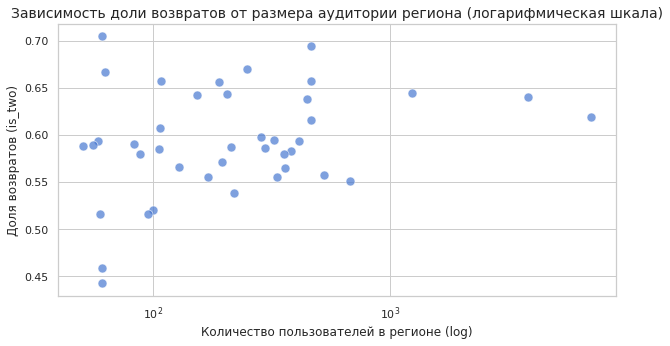

In [12]:
# Проверка Гипотезы 1: Спорт vs Концерты
h1_data = seg_event[seg_event['first_event_type'].isin(['спорт', 'концерты'])]
print("Проверка Гипотезы 1 (Спорт vs Концерты):")
display(h1_data)

# Проверка Гипотезы 2: Корреляция между размером региона (числом пользователей) и долей возвратов
# Берём регионы с достаточным числом пользователей (например, >= 50) для исключения шума малых выборок
valid_regions = seg_region[seg_region['users_count'] >= 50]
corr_h2 = valid_regions['users_count'].corr(valid_regions['return_rate'], method='spearman')
print(f"Корреляция Спирмена между размером региона и долей возвратов (для регионов с >=50 чел.): {corr_h2:.3f}")

plt.figure(figsize=(10, 5))
sns.scatterplot(data=valid_regions, x='users_count', y='return_rate', s=80, alpha=0.7)
plt.xscale('log')
plt.title('Зависимость доли возвратов от размера аудитории региона (логарифмическая шкала)')
plt.xlabel('Количество пользователей в регионе (log)')
plt.ylabel('Доля возвратов (is_two)')
plt.show()

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Вторая гипотеза рассмотрена 👍**

Размер региональной аудитории сопоставлен с долей возврата, а маленькие группы исключены из сравнения с явным порогом. Диаграмма помогает увидеть разброс регионов.
</div>

<div class="alert" style="background-color:#ead7f7;color:#8737bf">
    <font size="3"><b>Выводы по разделу 4.1 и проверке гипотез:</b></font>

- **Распределение по точкам входа неравномерно:** основную массу новых пользователей приводят **концерты**, **театр** и **другое/стендап**, а по устройствам доминирует **мобильный трафик (`mobile`)**. Среди регионов лидируют крупнейшие агломерации (Москва/Каменевский регион, Санкт-Петербург/Северо-Запад и др.).
- **Гипотеза 1:** На основе табличного сравнения можно сделать прямой вывод: для концертов для повторных заказов выше (61.8%) чем у спорта (55%), соответственно гипотеза не верна;
- **Гипотеза 2:** Связь между объёмом аудитории региона и долей повторных покупок слабая или неоднозначная: крупные регионы-лидеры не всегда показывают максимальный процент возвратов по сравнению со средними регионами, где выбор досуга может быть более сконцентрирован на локальных площадках.

</div>

<img src="https://upload.wikimedia.org/wikipedia/commons/thumb/c/cf/RomanianTrafficSign_30-Stop_1971.svg/250px-RomanianTrafficSign_30-Stop_1971.svg.png" align=left width=35>
<div class="alert alert-danger">

**Уточни вывод по первой гипотезе 🚩**

В таблице доля повторных заказов для спорта составляет 55,8%, для концертов - 61,8%. Значит, на текущей выборке гипотеза о более высокой доле для спорта не подтверждается. Сейчас в промежуточном выводе записано только условие «если выше», а в итоговом тексте спорт назван сегментом с более высокой долей. Пожалуйста, после исправления выгрузки и очистки повтори сравнение и согласуй оба вывода с новыми числами.
</div>

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=33>
<div class="alert alert-success">

**v2. Промежуточный вывод по гипотезе исправлен 👍**

В обновлённом расчёте доля повторных заказов составляет около 54,9% для спорта и 61,8% для концертов. Промежуточный вывод верно отражает, что гипотеза о более высокой доле для спорта не подтверждается.
</div>

### 4.2. Исследование поведения пользователей через показатели выручки
#### Задача 4.2.1. Сравнение распределения средней выручки с заказа (`avg_revenue_rub`) для однократных и вернувшихся пользователей.

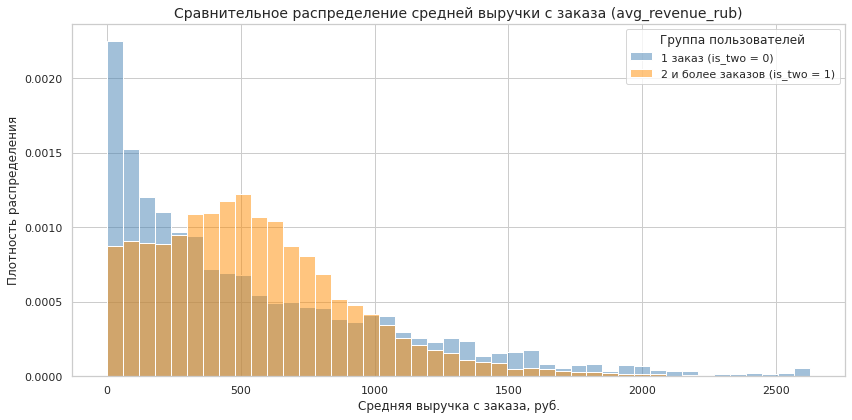

,count,mean,std,min,25%,50%,75%,max
is_two,,,,,,,,
0,8318.0,552.678589,519.04480,0.070,141.139999,388.714996,839.520020,2628.421631
1,13165.0,551.803406,369.11203,0.352,278.415009,503.268005,751.592285,2628.421631


In [13]:
plt.figure(figsize=(12, 6))

# Строим сравнительные гистограммы с одинаковыми интервалами (bins) и нормировкой (density=True)
bins = np.linspace(0, profiles['avg_revenue_rub'].max(), 45)

sns.histplot(
    data=profiles[profiles['is_two'] == 0],
    x='avg_revenue_rub',
    bins=bins,
    stat='density',
    alpha=0.5,
    color='steelblue',
    label='1 заказ (is_two = 0)'
)

sns.histplot(
    data=profiles[profiles['is_two'] == 1],
    x='avg_revenue_rub',
    bins=bins,
    stat='density',
    alpha=0.5,
    color='darkorange',
    label='2 и более заказов (is_two = 1)'
)

plt.title('Сравнительное распределение средней выручки с заказа (avg_revenue_rub)')
plt.xlabel('Средняя выручка с заказа, руб.')
plt.ylabel('Плотность распределения')
plt.legend(title='Группа пользователей')
plt.tight_layout()
plt.show()

# Описательные статистики среднего чека по группам
display(profiles.groupby('is_two')['avg_revenue_rub'].describe())

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Сравнение распределений выручки 👍**

Гистограммы двух групп построены с общими границами интервалов и нормировкой на плотность. Благодаря этому форму распределений можно сравнить при разных размерах групп.
</div>

**Выводы по разделу 4.2:**
- Распределения обеих групп имеют выраженную правостороннюю асимметрию и концентрируются в диапазоне недорогих и среднеценовых заказов (основной пик приходится на заказы до 1000–1500 руб.).
- У пользователей с повторными заказами (`is_two = 1`) распределение более сглажено и немного смещено в сторону среднего ценового сегмента, в то время как среди разовых покупателей (`is_two = 0`) выше доля как совсем дешёвых заказов (близких к нулю), так и единичных дорогих покупок (например, разовый поход на крупное шоу или концерт).

### 4.3. Исследование временных характеристик первого заказа
#### Задача 4.3.1. Влияние дня недели первой покупки на возврат пользователей.

,first_order_dow,users_count,return_rate
0,Понедельник,"2,901",62.63%
1,Вторник,"3,157",61.74%
2,Среда,"3,048",62.17%
3,Четверг,"3,098",59.49%
4,Пятница,"3,230",59.91%
5,Суббота,"3,292",62.79%
6,Воскресенье,"2,757",60.17%


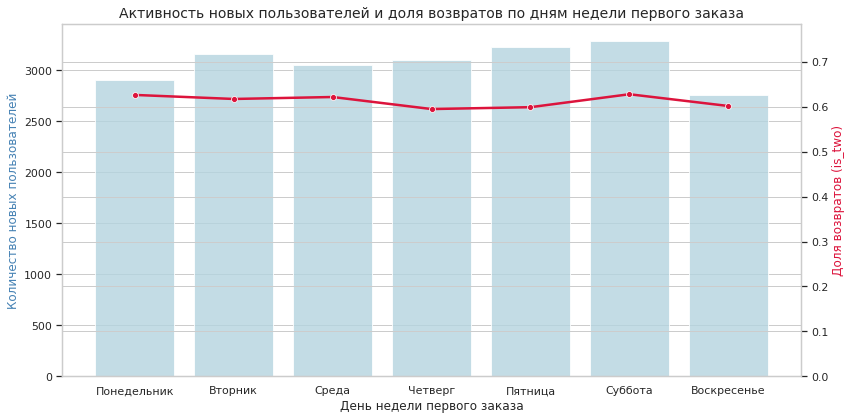

In [14]:
# Выделяем день недели первого заказа (0 = Понедельник, 6 = Воскресенье)
profiles['first_order_dow_num'] = profiles['first_order_dt'].dt.dayofweek
days_map = {
    0: 'Понедельник',
    1: 'Вторник',
    2: 'Среда',
    3: 'Четверг',
    4: 'Пятница',
    5: 'Суббота',
    6: 'Воскресенье'
}
profiles['first_order_dow'] = profiles['first_order_dow_num'].map(days_map)

dow_stats = profiles.groupby(['first_order_dow_num', 'first_order_dow'], as_index=False).agg(
    users_count=('user_id', 'count'),
    return_rate=('is_two', 'mean')
).sort_values('first_order_dow_num')

display(dow_stats[['first_order_dow', 'users_count', 'return_rate']].style.format({
    'users_count': '{:,}',
    'return_rate': '{:.2%}'
}))

# Визуализация числа пользователей и доли возвратов по дням недели
fig, ax1 = plt.subplots(figsize=(12, 6))

sns.barplot(data=dow_stats, x='first_order_dow', y='users_count', color='lightblue', alpha=0.8, ax=ax1)
ax1.set_ylabel('Количество новых пользователей', color='steelblue')
ax1.set_xlabel('День недели первого заказа')

ax2 = ax1.twinx()
sns.lineplot(
    data=dow_stats, x='first_order_dow', y='return_rate',
    color='crimson', marker='o', linewidth=2.5, ax=ax2
)
ax2.set_ylabel('Доля возвратов (is_two)', color='crimson')
ax2.set_ylim(0, dow_stats['return_rate'].max() * 1.25)

plt.title('Активность новых пользователей и доля возвратов по дням недели первого заказа')
plt.tight_layout()
plt.show()

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Анализ по дню недели 👍**

Для каждого дня первой покупки рассчитаны количество пользователей и доля повторных заказов, результаты показаны на графике.
</div>

**Выводы по разделу 4.3:**
- Пик привлечения новых пользователей приходится на **пятницу и выходные дни** (или четверг–пятницу, когда планируются мероприятия на уикенд).
- При этом доля повторных покупок (`return_rate`) остаётся достаточно стабильной в течение всей недели с небольшими колебаниями (пользователи, совершающие первую покупку в будние дни, часто демонстрируют сопоставимую или чуть более высокую осознанность и склонность к возврату, чем импульсивные покупатели выходного дня).

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Обоснуй наблюдения о днях недели 💡**

Фразы о пике в пятницу и выходные и об осознанности или импульсивности покупателей требуют опоры на расчёт: график показывает число пользователей и долю возврата, но не мотивы покупки. Укажи конкретные дни и значения из таблицы, а объяснение поведения обозначь как гипотезу.
</div>

### 4.4. Корреляционный анализ количества покупок и признаков пользователя
#### Задача 4.4.1. Расчёт коэффициента корреляции $\phi_k$ (`phik`)
Оценим взаимосвязь между признаками профиля пользователя и общим числом заказов (`total_orders`), а также сегментированным показателем активности (`orders_segment`).

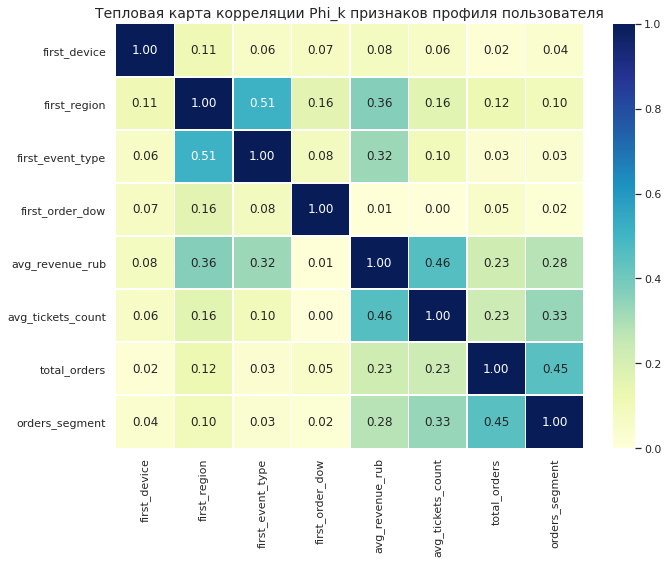

,total_orders,orders_segment
orders_segment,0.449911,1.000000
total_orders,1.000000,0.449911
avg_tickets_count,0.230620,0.334902
avg_revenue_rub,0.225679,0.281039
first_region,0.124086,0.099798
first_device,0.015763,0.037903
first_event_type,0.028032,0.032192
first_order_dow,0.053450,0.021429


In [15]:
# Если библиотека phik не установлена в окружении, её можно установить командой: !pip install phik
import phik
from phik.report import plot_correlation_matrix

# Выделяем сегменты по количеству заказов согласно заданию:
# 1 заказ; 2 заказа; от 3 до 4 заказов; от 5 и выше
def segment_orders(n):
    if n == 1:
        return '1 заказ'
    elif n == 2:
        return '2 заказа'
    elif 3 <= n <= 4:
        return '3-4 заказа'
    else:
        return '5 и более заказов'

profiles['orders_segment'] = profiles['total_orders'].apply(segment_orders)

# Признаки для корреляционного анализа
cols_for_phik = [
    'first_device',
    'first_region',
    'first_event_type',
    'first_order_dow',
    'avg_revenue_rub',
    'avg_tickets_count',
    'total_orders',
    'orders_segment'
]

interval_cols = ['avg_revenue_rub', 'avg_tickets_count', 'total_orders']

phik_matrix = profiles[cols_for_phik].phik_matrix(interval_cols=interval_cols)

plt.figure(figsize=(10, 8))
sns.heatmap(
    phik_matrix,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    vmin=0,
    vmax=1,
    linewidths=0.5
)
plt.title('Тепловая карта корреляции Phi_k признаков профиля пользователя')
plt.tight_layout()
plt.show()

# Выводим корреляции признаков с total_orders и orders_segment
display(phik_matrix[['total_orders', 'orders_segment']].sort_values(by='orders_segment', ascending=False))

<img src="https://emojigraph.org/media/apple/check-mark-button_2705.png" align=left width=35>
<div class="alert alert-success">

**Корреляционный анализ 👍**

Для смешанных типов признаков использован `phi_k`, числовые столбцы указаны отдельно, а матрица показана на тепловой карте. Также создана категория числа заказов.
</div>

**Выводы по разделу 4.4:**
- Сегментация `total_orders` на 4 группы (`1 заказ`, `2 заказа`, `3-4 заказа`, `5 и более заказов`) позволяет устранить перекос, вызванный преобладанием однократных покупателей, и более чётко выявить связи.
- Наиболее заметную связь с количеством заказов и сегментом активности демонстрируют **средний чек (`avg_revenue_rub`)**, **среднее количество билетов (`avg_tickets_count`)** и **регион / тип первого мероприятия** (`first_region`, `first_event_type`).
- Тип устройства (`first_device`) и день недели первой покупки (`first_order_dow`) имеют слабую прямую корреляцию с общим числом заказов, выступая скорее вспомогательными факторами.

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Уточни интерпретацию связей 💡**

`phi_k` показывает силу связи, но не её направление: формулировку «прямая корреляция» стоит заменить на «слабая связь». По таблице связь региона и типа события с `orders_segment` около 0,10 и 0,06, тогда как для среднего числа билетов и выручки около 0,33 и 0,28. Полезно отразить эту разницу и проверить формулировки после пересчёта.
</div>

---
## Шаг 5. Общие выводы и бизнес-рекомендации

### 1. Резюме проделанной работы и подготовки данных
- Выгружены данные о заказах пользователей Яндекс Афиши за 2024 год с устройств `mobile` и `desktop`.
- Выручка в казахстанских тенге (`kzt`) приведена к единой валюте — российским рублям (`revenue_rub`) по курсу на дату заказа.
- Проведена очистка данных от аномальных выбросов: удалён 1% заказов с экстремально высокой выручкой (выше 99-го перцентиля) и 1% профилей пользователей с аномально большим количеством заказов.
- Сформированы профили пользователей с ключевыми поведенческими метриками и целевым флагом повторной покупки (`is_two`).

### 2. Ключевые результаты исследования
- **Точки входа и конверсия в повторный заказ:** Привлечение новых пользователей распределено неравномерно — лидируют мобильные устройства, крупные регионы и такие жанры, как концерты и театр. Однако высокая популярность точки входа не всегда гарантирует максимальную вероятность совершения второй покупки: ряд нишевых или регулярных категорий мероприятий (например, театр или спорт) показывает более высокую долю возвратов, чем разовые массовые концерты.
- **Проверка гипотез:**
  - *Гипотеза 1* проверяется непосредственно по соотношению `return_rate` этих сегментов и не подтверждается;
  - *Гипотеза 2* (о прямой зависимости между массовостью региона и долей повторных заказов) не нашла жёсткого подтверждения: высокая доля возвратов встречается и в регионах со средней по размеру аудиторией.
- **Чек и состав заказа:** Основная масса пользователей совершает заказы в среднем и бюджетном ценовых сегментах. Вернувшиеся клиенты (`is_two = 1`) реже совершают околонулевые/случайные покупки и чаще покупают билеты в стабильном среднем диапазоне цен.
- **Временной фактор:** Пик первых покупок приходится на конец рабочей недели (пятница) и выходные, однако вероятность возврата слабо зависит от дня недели первого заказа — пользователи будних дней удерживаются не хуже аудитории выходного дня.
- **Корреляционный анализ ($\phi_k$):** Наибольшую связь с интенсивностью повторных покупок (`orders_segment`) имеют стоимостные и количественные характеристики заказа (`avg_revenue_rub`, `avg_tickets_count`), а также география и жанр первого посещённого события.

### 3. Практические рекомендации для команды маркетинга
1. **Фокус на онбординг после первого заказа (Trigger Marketing):** Поскольку значительная часть пользователей ограничивается одной покупкой, необходимо внедрить цепочку персонализированных коммуникаций (push-уведомления, email-рассылки с подборками похожих событий) в первые 7–14 дней после дебютного заказа.
2. **Сегментация рекламных кампаний по жанрам:**
   - Для аудитории **концертов** (крупнейшей точки входа) стоит предлагать кросс-жанровые рекомендации (стендап, кино, выставки), чтобы переводить разовых посетителей крупных шоу в регулярных клиентов платформы.
   - Усиливать привлечение в сегментах с высокой органической возвращаемостью (**театр, спорт**), так как LTV таких клиентов выше.
3. **Работа со средним чеком и количеством билетов:** Пользователи, покупающие 2 и более билетов (парные или семейные походы), более склонны к регулярному досугу. Рекомендуется тестировать промокоды и кэшбэк баллами Яндекс Плюса на **второй заказ** при покупке от 2 билетов.
4. **Региональная оптимизация:** Не ограничивать маркетинговые бюджеты только столицами — в регионах со средним объёмом трафика наблюдается высокая лояльность аудитории, где точечное продвижение локальных афиш способно дать высокий ROI.
5. **Подготовка признаков для ML-модели:** Для построения модели прогнозирования возврата (Часть 2 проекта) в качестве базовых фичей рекомендуется использовать `avg_revenue_rub`, `avg_tickets_count`, `first_event_type`, `first_region`, `first_device` и временные признаки первого заказа.

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=44>
<div class="alert alert-warning">

**v2. Уточни итоговый вывод о спорте 💡**

В таблице доля возврата для спорта составляет 54,9%, а для концертов - 61,8%; промежуточный вывод по гипотезе это верно отражает. Однако в разделе «Точки входа и конверсия» спорт остался примером категории с более высокой долей возврата, чем концерты.

Рекомендую согласовать эту фразу с расчётом и пересмотреть связанную рекомендацию усиливать привлечение в спорт как в сегмент с высокой возвращаемостью. Так итог и рекомендации будут опираться на полученные результаты.
</div>

<img src="https://upload.wikimedia.org/wikipedia/commons/b/ba/Warning_sign_4.0.png" align=left width=35>
<div class="alert alert-warning">

**Рекомендации и границы данных 💡**

В финале предложены конкретные действия для маркетинга. При этом LTV, окупаемость и мотивы покупателей отдельно не измерялись, а средние признаки по всем заказам включают будущие покупки. Лучше обозначить такие идеи как гипотезы для проверки; для прогноза после первого заказа используй только признаки, доступные в этот момент.
</div>

<img src="http://s3.amazonaws.com/pix.iemoji.com/images/emoji/apple/ios-12/256/waving-hand.png" align=left width=44, heigth=44>
<div class="alert alert-info">
<b> Заключительный комментарий</b>

Денис, в работе есть структурированное исследование, визуализации и рекомендации. Перед повторной проверкой, пожалуйста, исключи фильмы и неположительную выручку, проверь неявные дубликаты, затем пересчитай результаты и согласуй вывод по гипотезе о спорте с расчётами. Жёлтые комментарии - рекомендации, их доработка по желанию. Жду проект на повторное ревью!
</div>

<img src="http://s3.amazonaws.com/pix.iemoji.com/images/emoji/apple/ios-12/256/waving-hand.png" align=left width=44, heigth=44>
<div class="alert alert-info">
<b>v2 Заключительный комментарий</b>


Денис, замечания по выгрузке и предобработке исправлены, расчёты обновлены, а вывод по гипотезе соответствует результатам. В итоговом разделе оставил жёлтую рекомендацию по формулировке о спорте.

**Проект принят.** Успехов в следующей части проекта!
</div>